In [1]:
import duckdb as db
import numpy as np
import pandas as pd
import json
import arrow
import pyarrow as pa
import pyarrow.parquet as pq

## Feature Engineering

Script builds the files needed for running some unsupervised models

Focus is on identifying fields that should be consistent across implementations

In [4]:
saas_customers = ['jaguar','locusbio','seres','tenaya']

saas = 'seres'

In [5]:
dat = db.sql(f"select * from read_parquet('C:/MLAR_DATA/T0001/MLAR_RAW_{saas}.parquet')").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [4]:
print(dat.columns.values)

['audit_table_name' 'audit_action' 'audit_timestamp' 'audit_type'
 'audit_counter' 'trans_order' 'table_name' 'table_key' 'reason'
 'record_signed' 'user_name' 'user_role' 'parent_table' 'parent_key'
 'batch_name' 'col_num' 'document_number' 'experiment_number' 'row_num'
 'workbook_number' 'worksheet' 'formulation' 'investigation' 'order_num'
 'project_name' 'name' 'report_number' 'sample_number' 'location_number'
 't_mlar' 't_mlar_severity' 'SAMPLE_NUMBER_norm' 'TEST_NUMBER_norm'
 'RESULT_NUMBER_norm' 'ORDER_NUMBER_norm' 'ANALYSIS_norm' 'NAME_norm'
 'REPORTED_NAME_norm' 'REPLICATE_COUNT_norm' 'RESULT_TYPE_norm'
 'STATUS_norm' 'OLD_STATUS_norm' 'MODIFIED_RESULT_norm' 'ALLOW_OUT_norm'
 'UNITS_norm' 'ROUND_norm' 'PLACES_norm' 'IN_SPEC_norm'
 'PRIMARY_IN_SPEC_norm' 'USES_INSTRUMENT_norm' 'USES_CODES_norm'
 'IN_CAL_norm' 'AUTO_CALC_norm' 'ALLOW_CANCEL_norm' 'LINK_SIZE_norm'
 'REPORTABLE_norm' 'OPTIONAL_norm' 'CODE_ENTERED_norm' 'CHANGED_ON_norm'
 'STD_REAG_SAMPLE_norm' 'HAS_ATTRIBUTES_norm

In [19]:
engineered_features = db.sql(f"select sample_number, count(*) as audit_count, max(audit_timestamp) as last_audit_date, min(audit_timestamp) as first_audit_date, count(distinct user_name) as distinct_users, count(distinct name_norm) as distinct_result_names from read_parquet('C:/MLAR_DATA/T0001/MLAR_RAW_{saas}.parquet') group by sample_number").to_df()
engineered_features['seconds_to_process'] = (engineered_features['last_audit_date'] - engineered_features['first_audit_date']).dt.total_seconds()
engineered_features['seconds_to_process'].replace(0, 1, inplace=True)
engineered_features['volacity'] = engineered_features['audit_count'] / ((engineered_features['seconds_to_process']) / 3600)

In [51]:
test_features = db.sql("select sample_number,table_key, count(*) as audit_count, max(audit_timestamp) as last_audit_date, min(audit_timestamp) as first_audit_date from read_parquet('C:/MLAR_DATA/T0001/MLAR_RAW_tenaya.parquet') where table_name = 'TEST' group by sample_number, table_key").to_df()


In [25]:
fields = {'sample_number','audit_action','audit_timestamp','audit_type','audit_counter','trans_order','table_name',
               'record_signed','user_role','STATUS_norm','OLD_STATUS_norm','IN_SPEC_norm','IN_CAL_norm','RE_SAMPLE_norm',
               'ORIGINAL_SAMPLE_norm','ALIQUOT_norm','PARENT_SAMPLE_norm','PARENT_ALIQUOT_norm','LOGIN_DATE_norm','LOGIN_BY_norm',
               'RECD_DATE_norm','RECEIVED_BY_norm','DATE_STARTED_norm',
                'DATE_COMPLETED_norm',
                'DATE_REVIEWED_norm',
                #'PREP_DATE_norm',
                #'PREP_BY_norm',
                'PRODUCT_VERSION_norm',
                #'PROJECT_norm',
                #'BATCH_NAME_norm',
                #'BATCH_TEMPLATE_norm',
                #'STEP_norm',
                #'SAMPLE_TYPE_norm',
                'TEMPLATE_norm',
                'STANDARD_norm',
                'LOT_norm',
                'CHANGED_ON_norm',
                'PARTIAL_SPEC_norm',
                'PRIMARY_IN_SPEC_norm',
                'BATCH_norm',
                #'PROTOCOL_LEVEL_norm',
                'RELEASED_norm',
                'RELEASED_BY_norm',
                'RELEASED_ON_norm',
                'IN_CONTROL_norm',
                #'INVESTIGATION_norm',
                'INVESTIGATED_norm',
                'MODIFIED_RESULTS_norm',
                'COMPOSITE_norm',
                'PARENT_COMPOSITE_norm',
                'HAS_FLAGS_norm',
                #'IMPORTANT_MESSAGE_norm',
                'SIGNED_norm',
                'TEST_NUMBER_norm',
                'CHARGE_ENTRY_norm',
                'ANALYSIS_norm',
                'VERSION_norm',
                'SAMPLE_NUMBER_norm',
                'REPLICATE_COUNT_norm',
                'DATE_RECEIVED_norm',
                'DATE_STARTED_norm',
                #'PREP_norm',
                #'PREP_DATE_norm',
                #'PREP_BY_norm',
                'DATE_COMPLETED_norm',
                'DATE_REVIEWED_norm',
                'REVIEWER_norm',
                'REPLICATE_TEST_norm',
                'IN_SPEC_norm',
                'IN_CAL_norm',
                'ORDER_NUMBER_norm',
                'GROUP_NAME_norm',
                'RESOLVE_REQD_norm',
                'CHANGED_ON_norm',
                'STAGE_norm',
                'PRIMARY_IN_SPEC_norm',
                'BATCH_norm',
                'IN_CONTROL_norm',
                #'VARIATION_norm',
                'RE_TESTED_norm',
                #'TEST_LIST_norm',
                'MODIFIED_RESULTS_norm',
                'ALIQUOTED_TO_norm',
                'ON_WORKSHEET_norm',
                'ANALYSIS_COUNT_norm',
                'BATCH_ORIGINAL_TEST_norm',
                'BATCH_PARENT_TEST_norm',
                'CHILD_OUT_SPEC_norm',
                'CROSS_SAMPLE_norm',
                'ORIGINAL_TEST_norm',
                'PARENT_TEST_norm',
                'RELEASED_norm',
                'RELEASED_BY_norm',
                'RELEASED_ON_norm',
                'SIGNED_norm',
                'RESULT_NUMBER_norm',
                'TEST_NUMBER_norm',
                'NAME_norm',
                'REPLICATE_COUNT_norm',
                'ORDER_NUMBER_norm',
                'RESULT_TYPE_norm',
                'MINIMUM_norm',
                'MAXIMUM_norm',
                'ALLOW_OUT_norm',
                'FORMATTED_ENTRY_norm',
                'NUMERIC_ENTRY_norm',
                'PLACES_norm',
                'ENTERED_ON_norm',
                'ENTERED_BY_norm',
                'USES_CODES_norm',
                'AUTO_CALC_norm',
                'LIST_KEY_norm',
                'ALLOW_CANCEL_norm',
                'IN_SPEC_norm',
                'REPORTABLE_norm',
                'OPTIONAL_norm',
                'CODE_ENTERED_norm',
                'ROUND_norm',
                'DATE_REVIEWED_norm',
                'REVIEWER_norm',
                'CHANGED_ON_norm',
                'STD_REAG_SAMPLE_norm',
                'DISPLAYED_norm',
                'ENTRY_QUALIFIER_norm',
                #'INSTRUMENT_norm',
                'SAMPLE_NUMBER_norm',
                'ANALYSIS_norm',
                'USES_INSTRUMENT_norm',
                'IN_CAL_norm',
                'HAS_ATTRIBUTES_norm',
                #'FACTOR_OPERATOR_norm',
                'ENTRY_TYPE_norm',
                #'ALIAS_NAME_norm',
                'CONTROL_1_norm',
                #'CONTROL_2_norm',
                'IN_CONTROL_norm',
                'REPORTED_NAME_norm',
                'PRIMARY_IN_SPEC_norm'}


In [ ]:
mod_dat = pd.merge(mod_dat,engineered_features, on='sample_number')


In [11]:
table = pa.Table.from_pandas(mod_dat)

In [18]:
mod_dat['STATUS_norm'].value_counts()

STATUS_norm
N    83458
I    69163
A    67096
U    43161
E    42380
C    37081
X     9784
P     1471
M     1062
R      628
Name: count, dtype: int64

In [54]:
pq.write_table(table,f'C:/MLAR_DATA/for_model/T0001/{saas}_model_ready.parquet')

<Axes: >

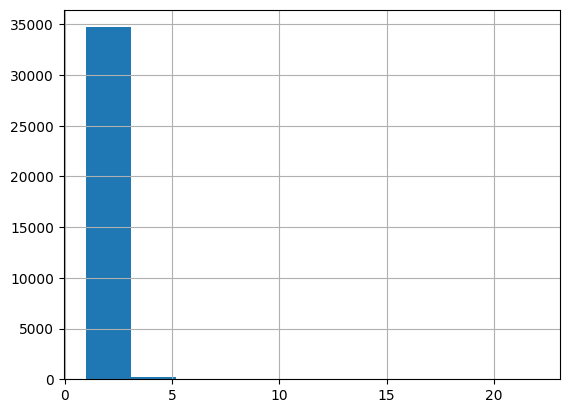

In [60]:
test_features['audit_count'].hist()

In [61]:
print(dat.columns.values)

['audit_table_name' 'audit_action' 'audit_timestamp' 'audit_type'
 'audit_counter' 'trans_order' 'table_name' 'table_key' 'reason'
 'record_signed' 'user_name' 'user_role' 'parent_table' 'parent_key'
 'batch_name' 'col_num' 'document_number' 'experiment_number' 'row_num'
 'workbook_number' 'worksheet' 'formulation' 'investigation' 'order_num'
 'project_name' 'name' 'report_number' 'sample_number' 'location_number'
 't_mlar' 't_mlar_severity' 'SAMPLE_NUMBER_norm' 'TEST_NUMBER_norm'
 'RESULT_NUMBER_norm' 'ORDER_NUMBER_norm' 'ANALYSIS_norm' 'NAME_norm'
 'REPORTED_NAME_norm' 'REPLICATE_COUNT_norm' 'RESULT_TYPE_norm'
 'STATUS_norm' 'OLD_STATUS_norm' 'MODIFIED_RESULT_norm' 'ALLOW_OUT_norm'
 'UNITS_norm' 'ROUND_norm' 'PLACES_norm' 'IN_SPEC_norm'
 'PRIMARY_IN_SPEC_norm' 'USES_INSTRUMENT_norm' 'USES_CODES_norm'
 'IN_CAL_norm' 'AUTO_CALC_norm' 'ALLOW_CANCEL_norm' 'LINK_SIZE_norm'
 'REPORTABLE_norm' 'OPTIONAL_norm' 'CODE_ENTERED_norm' 'CHANGED_ON_norm'
 'STD_REAG_SAMPLE_norm' 'HAS_ATTRIBUTES_norm

In [65]:
dat['STAGE_norm'].value_counts()

STAGE_norm
SURF_TSA_AE    18448
SURF_TSA_AN    18442
PDMS           11799
NONE           10364
AIR_TSA_AN      8028
AIR             8026
AIR_TSA_AE      8026
WATER           2586
SURF_SDA        1900
SWAB            1520
AIR_SDA         1244
SETTLE           762
PERSON           508
WATER_TOC        252
WATER_COND       252
GRMS-GPS         197
PRMS             186
DP               156
FRMS             124
GRMS             124
FB               124
RETAINED         117
DS                66
PIS               30
WS                28
PS                20
CS-GPS            20
WS-GPS            20
DCS               20
CS                18
Name: count, dtype: int64

<Axes: >

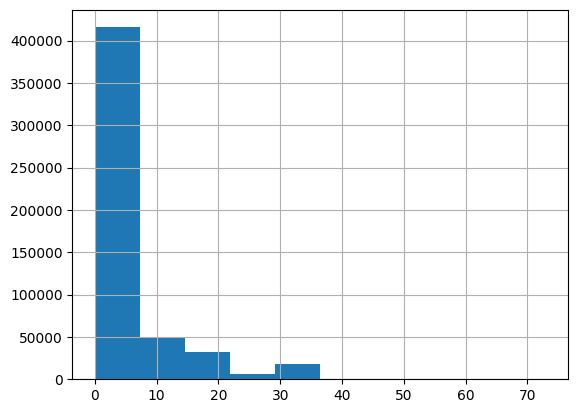

In [58]:
mod_dat['distinct_result_names'].hist()

In [67]:
dat['STAGE_norm'].isna().sum()

430053

In [68]:
len(dat)

523460

In [15]:
saas_customers = ['jaguar','locusbio','seres','tenaya']
fields = {'sample_number','audit_action','audit_timestamp','audit_type','audit_counter','trans_order','table_name',
               'record_signed','user_role','STATUS_norm','OLD_STATUS_norm','IN_SPEC_norm','IN_CAL_norm','RE_SAMPLE_norm',
               'ORIGINAL_SAMPLE_norm','ALIQUOT_norm','PARENT_SAMPLE_norm','PARENT_ALIQUOT_norm','LOGIN_DATE_norm','LOGIN_BY_norm',
               'RECD_DATE_norm','RECEIVED_BY_norm','DATE_STARTED_norm',
                'DATE_COMPLETED_norm', 'DATE_REVIEWED_norm',
                #'PREP_DATE_norm',
                #'PREP_BY_norm',
                'PRODUCT_VERSION_norm',
                #'PROJECT_norm',
                #'BATCH_NAME_norm',
                #'BATCH_TEMPLATE_norm',
                #'STEP_norm',
                #'SAMPLE_TYPE_norm',
                'TEMPLATE_norm',
                'STANDARD_norm',
                'LOT_norm',
                'CHANGED_ON_norm',
                'PARTIAL_SPEC_norm',
                'PRIMARY_IN_SPEC_norm',
                'BATCH_norm',
                #'PROTOCOL_LEVEL_norm',
                'RELEASED_norm',
                #'RELEASED_BY_norm',
                #'RELEASED_ON_norm',
                'IN_CONTROL_norm',
                #'INVESTIGATION_norm',
                'INVESTIGATED_norm',
                'MODIFIED_RESULTS_norm',
                'COMPOSITE_norm',
                'PARENT_COMPOSITE_norm',
                'HAS_FLAGS_norm',
                #'IMPORTANT_MESSAGE_norm',
                'SIGNED_norm',
                'TEST_NUMBER_norm',
                'CHARGE_ENTRY_norm',
                'ANALYSIS_norm',
                'VERSION_norm',
                'SAMPLE_NUMBER_norm',
                'REPLICATE_COUNT_norm',
                'DATE_RECEIVED_norm',
                'DATE_STARTED_norm',
                #'PREP_norm',
                #'PREP_DATE_norm',
                #'PREP_BY_norm',
                'DATE_COMPLETED_norm',
                'DATE_REVIEWED_norm',
                'REVIEWER_norm',
                'REPLICATE_TEST_norm',
                'IN_SPEC_norm',
                'IN_CAL_norm',
                'ORDER_NUMBER_norm',
                'GROUP_NAME_norm',
                'RESOLVE_REQD_norm',
                'CHANGED_ON_norm',
                'STAGE_norm',
                'PRIMARY_IN_SPEC_norm',
                'BATCH_norm',
                'IN_CONTROL_norm',
                #'VARIATION_norm',
                'RE_TESTED_norm',
                #'TEST_LIST_norm',
                'MODIFIED_RESULTS_norm',
                'ALIQUOTED_TO_norm',
                'ON_WORKSHEET_norm',
                'ANALYSIS_COUNT_norm',
                'BATCH_ORIGINAL_TEST_norm',
                'BATCH_PARENT_TEST_norm',
                'CHILD_OUT_SPEC_norm',
                'CROSS_SAMPLE_norm',
                'ORIGINAL_TEST_norm',
                'PARENT_TEST_norm',
                'RELEASED_norm',
                #'RELEASED_BY_norm',
                #'RELEASED_ON_norm',
                'SIGNED_norm',
                'RESULT_NUMBER_norm',
                'TEST_NUMBER_norm',
                'NAME_norm',
                'REPLICATE_COUNT_norm',
                'ORDER_NUMBER_norm',
                'RESULT_TYPE_norm',
                #'MINIMUM_norm',
                #'MAXIMUM_norm',
                'ALLOW_OUT_norm',
                'FORMATTED_ENTRY_norm',
                'NUMERIC_ENTRY_norm',
                'PLACES_norm',
                'ENTERED_ON_norm',
                'ENTERED_BY_norm',
                'USES_CODES_norm',
                'AUTO_CALC_norm',
                'LIST_KEY_norm',
                'ALLOW_CANCEL_norm',
                'IN_SPEC_norm',
                'REPORTABLE_norm',
                'OPTIONAL_norm',
                'CODE_ENTERED_norm',
                'ROUND_norm',
                'DATE_REVIEWED_norm',
                'REVIEWER_norm',
                'CHANGED_ON_norm',
                'STD_REAG_SAMPLE_norm',
                'DISPLAYED_norm',
                'ENTRY_QUALIFIER_norm',
                #'INSTRUMENT_norm',
                'SAMPLE_NUMBER_norm',
                'ANALYSIS_norm',
                'USES_INSTRUMENT_norm',
                'IN_CAL_norm',
                'HAS_ATTRIBUTES_norm',
                #'FACTOR_OPERATOR_norm',
                'ENTRY_TYPE_norm',
                #'ALIAS_NAME_norm',
                'CONTROL_1_norm',
                #'CONTROL_2_norm',
                'IN_CONTROL_norm',
                'REPORTED_NAME_norm',
                'PRIMARY_IN_SPEC_norm',
                'reason'}

In [16]:
fields= list(fields)

In [17]:
len(fields)

90

In [18]:

def data_engineering(saas):
    dat = db.sql(f"select * from read_parquet('C:/MLAR_DATA/T0001/MLAR_RAW_{saas}.parquet')").to_df()
    engineered_features = db.sql(f"select sample_number, count(*) as audit_count, max(audit_timestamp) as last_audit_date, min(audit_timestamp) as first_audit_date, count(distinct user_name) as distinct_users, count(distinct name_norm) as distinct_result_names from read_parquet('C:/MLAR_DATA/T0001/MLAR_RAW_{saas}.parquet') group by sample_number").to_df()
    engineered_features['seconds_to_process'] = (engineered_features['last_audit_date'] - engineered_features['first_audit_date']).dt.total_seconds()
    engineered_features['seconds_to_process'].replace(0, 1, inplace=True)
    engineered_features['volacity'] = engineered_features['audit_count'] / ((engineered_features['seconds_to_process']) / 3600)
    mod_dat = dat[fields]
    mod_dat = pd.merge(mod_dat,engineered_features, on='sample_number')
    mod_dat['seconds_since_start'] = (mod_dat['audit_timestamp'] - mod_dat['first_audit_date']).dt.total_seconds()
    mod_dat['status_no_change'] = np.where(mod_dat["STATUS_norm"] == mod_dat['OLD_STATUS_norm'],"Yes", "No")
    mod_dat['customer'] = saas 
    table = pa.Table.from_pandas(mod_dat)
    pq.write_table(table,f'C:/MLAR_DATA/for_model/T0001/{saas}_model_ready.parquet')
    

In [19]:
for saas in saas_customers:
    data_engineering(saas)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Do some assessment of the quality of each system

- status 
- daily transactions
- 